# Cora Node Classification: MLP vs GCN vs GAT vs SCORE

## Project Overview

This project investigates node classification on the Cora
citation network using four approaches:

- MLP: Feature-based learning.
- GCN: Graph convolutional learning.
- GAT: Attention-based graph learning.
- SCORE: Spectral community detection.

## Objectives

1. Explore the Cora citation network.
2. Analyze node features and graph structure.
3. Compare feature-based and graph-based learning.
4. Evaluate neural graph models against spectral clustering.

In [1]:
# ==========================================
# 1. Imports
# ==========================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import torch
import torch_geometric
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import networkx as nx

# ==========================================
# 2. Locate project directory
# ==========================================

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src").exists():
    raise FileNotFoundError("Project root not found!")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# ==========================================
# 3. Import project configuration
# ==========================================

from src.config import (
    PROJECT_ROOT,
    DATA_DIR,
    CHECKPOINT_DIR,
    FIGURE_DIR,
    METRICS_DIR,
    SEED
)

from src.utils import (
    set_seed,
    get_device,
    create_project_dirs
)

# ==========================================
# 4. Initialize environment
# ==========================================

set_seed(SEED)

create_project_dirs()

device = get_device()

# ==========================================
# 5. Check environment
# ==========================================

print("Python executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

print("Device:", device)
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

print("\nEnvironment initialized successfully!")

c:\Users\ASUS\Documents\Projects\Cora-Node Classy\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python executable: c:\Users\ASUS\Documents\Projects\Cora-Node Classy\.venv\Scripts\python.exe
PyTorch: 2.15.0+cpu
PyG: 2.8.1
NumPy: 2.5.4
SciPy: 1.18.1
Device: cpu
Project root: C:\Users\ASUS\Documents\Projects\Cora-Node Classy
Data directory: C:\Users\ASUS\Documents\Projects\Cora-Node Classy\data

Environment initialized successfully!


In [2]:
# Datacheck

from src.data import load_cora, get_dataset_info

dataset, data = load_cora()

info = get_dataset_info(dataset, data)

for key, value in info.items():
    print(f"{key}: {value}")

num_nodes: 2708
edge_index_entries: 10556
undirected_edges: 5278
num_features: 1433
num_classes: 7
train_nodes: 140
val_nodes: 500
test_nodes: 1000
num_components: 78
smallest_component_size: 2
largest_component_size: 2485


In [3]:
#Check

print("Feature shape:", data.x.shape)
print("Edge index shape:", data.edge_index.shape)
print("Labels shape:", data.y.shape)

print("Train nodes:", data.train_mask.sum().item())
print("Validation nodes:", data.val_mask.sum().item())
print("Test nodes:", data.test_mask.sum().item())

print("Undirected graph:", data.is_undirected())
print("Contains self-loops:", data.contains_self_loops())
print("Contains isolated nodes:", data.has_isolated_nodes())

Feature shape: torch.Size([2708, 1433])
Edge index shape: torch.Size([2, 10556])
Labels shape: torch.Size([2708])
Train nodes: 140
Validation nodes: 500
Test nodes: 1000
Undirected graph: True
Contains self-loops: False
Contains isolated nodes: False


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19008\493471000.py:12: UserWarning: 'contains_self_loops' is deprecated, use 'has_self_loops' instead
  print("Contains self-loops:", data.contains_self_loops())


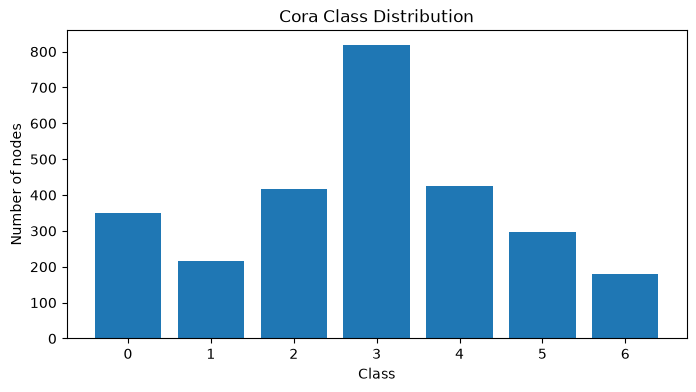

In [4]:
# Label Distribution

class_counts = torch.bincount(
    data.y,
    minlength=dataset.num_classes
)

plt.figure(figsize=(8, 4))

plt.bar(
    range(dataset.num_classes),
    class_counts.numpy()
)

plt.xlabel("Class")
plt.ylabel("Number of nodes")
plt.title("Cora Class Distribution")
plt.xticks(range(dataset.num_classes))

plt.show()

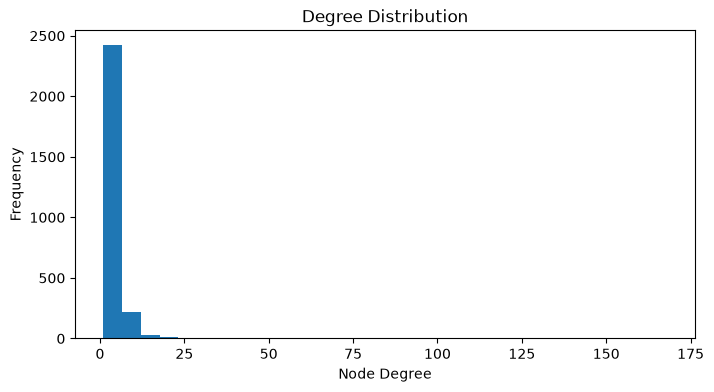

Average degree: 3.8980798721313477
Maximum degree: 168.0
Minimum degree: 1.0


In [5]:
# Degree Distribution

from torch_geometric.utils import degree
node_degree = degree(
    data.edge_index[0],
    num_nodes=data.num_nodes
)

plt.figure(figsize=(8, 4))

plt.hist(
    node_degree.numpy(),
    bins=30
)

plt.xlabel("Node Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution")

plt.show()

print("Average degree:", node_degree.mean().item())
print("Maximum degree:", node_degree.max().item())
print("Minimum degree:", node_degree.min().item())

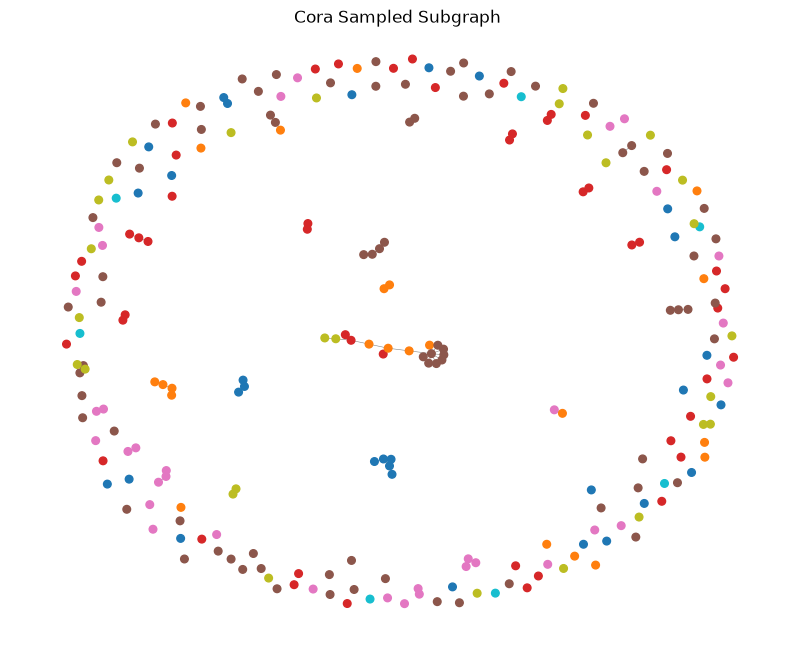

In [6]:
#Sample Graph

rng = np.random.default_rng(SEED)

sample_size = min(250, data.num_nodes)

sample_nodes = rng.choice(
    data.num_nodes,
    size=sample_size,
    replace=False
)

sample_nodes = set(sample_nodes.tolist())

edge_array = data.edge_index.cpu().numpy().T

graph = nx.Graph()

graph.add_nodes_from(sample_nodes)

for source, target in edge_array:
    if source in sample_nodes and target in sample_nodes:
        graph.add_edge(source, target)

positions = nx.spring_layout(
    graph,
    seed=SEED
)

node_colors = [
    int(data.y[node])
    for node in graph.nodes()
]

plt.figure(figsize=(10, 8))

nx.draw_networkx(
    graph,
    positions,
    node_size=30,
    node_color=node_colors,
    with_labels=False,
    cmap=plt.cm.tab10,
    edge_color="gray",
    width=0.4
)

plt.title("Cora Sampled Subgraph")
plt.axis("off")
plt.show()

In [7]:
print("Full Cora Graph")
print("Number of nodes:", data.num_nodes)
print("Number of edges:", data.edge_index.size(1) // 2)
print("Number of features:", data.x.size(1))
print("Number of classes:", dataset.num_classes)

print("\nPublic Masks")
print("Train:", data.train_mask.sum().item())
print("Validation:", data.val_mask.sum().item())
print("Test:", data.test_mask.sum().item())

train_mask = data.train_mask
val_mask = data.val_mask
test_mask = data.test_mask

assert data.num_nodes == 2708
assert data.x.size(1) == 1433
assert dataset.num_classes == 7

assert train_mask.sum().item() == 140
assert val_mask.sum().item() == 500
assert test_mask.sum().item() == 1000

assert not (train_mask & val_mask).any()
assert not (train_mask & test_mask).any()
assert not (val_mask & test_mask).any()

train_class_counts = torch.bincount(
    data.y[train_mask],
    minlength=dataset.num_classes
)

print("\nTraining class distribution:")
for class_id, count in enumerate(train_class_counts):
    print(f"Class {class_id}: {count.item()}")

assert (train_class_counts > 0).all()

print("\nFull graph and masks validation passed.")

Full Cora Graph
Number of nodes: 2708
Number of edges: 5278
Number of features: 1433
Number of classes: 7

Public Masks
Train: 140
Validation: 500
Test: 1000

Training class distribution:
Class 0: 20
Class 1: 20
Class 2: 20
Class 3: 20
Class 4: 20
Class 5: 20
Class 6: 20

Full graph and masks validation passed.


In [8]:
# Graph to Device

data = data.to(device)

num_features = data.x.size(1)
num_classes = dataset.num_classes

print("Number of nodes:", data.num_nodes)
print("Number of features:", num_features)
print("Number of classes:", num_classes)
print("Device:", device)

Number of nodes: 2708
Number of features: 1433
Number of classes: 7
Device: cpu


In [10]:
# Model test

from src.models import MLP, GCN, GAT
from src.utils import count_parameters

test_models = {
    "MLP": MLP(
        in_channels=num_features,
        hidden_channels=64,
        out_channels=num_classes,
        dropout=0.5
    ),

    "GCN": GCN(
        in_channels=num_features,
        hidden_channels=64,
        out_channels=num_classes,
        dropout=0.5
    ),

    "GAT": GAT(
        in_channels=num_features,
        hidden_channels=8,
        out_channels=num_classes,
        heads=8,
        dropout=0.6
    )
}

for model_name, model in test_models.items():

    model = model.to(device)
    model.eval()

    with torch.no_grad():
        output = model(
            data.x,
            data.edge_index
        )

    print("=" * 40)
    print("Model:", model_name)
    print("Output shape:", output.shape)
    print("Parameters:", count_parameters(model))

Model: MLP
Output shape: torch.Size([2708, 7])
Parameters: 92231
Model: GCN
Output shape: torch.Size([2708, 7])
Parameters: 92231
Model: GAT
Output shape: torch.Size([2708, 7])
Parameters: 92373


In [11]:
model_configs = {
    "MLP": {
        "class": MLP,

        "kwargs": {
            "in_channels": num_features,
            "hidden_channels": 64,
            "out_channels": num_classes,
            "dropout": 0.5
        },

        "learning_rate": 0.01,
        "weight_decay": 5e-4
    },

    "GCN": {
        "class": GCN,

        "kwargs": {
            "in_channels": num_features,
            "hidden_channels": 64,
            "out_channels": num_classes,
            "dropout": 0.5
        },

        "learning_rate": 0.01,
        "weight_decay": 5e-4
    },

    "GAT": {
        "class": GAT,

        "kwargs": {
            "in_channels": num_features,
            "hidden_channels": 8,
            "out_channels": num_classes,
            "heads": 8,
            "dropout": 0.6
        },

        "learning_rate": 0.005,
        "weight_decay": 5e-4
    }
}


Training MLP
MLP | Epoch 010 | Train Loss: 1.8553 | Val Acc: 0.4180
MLP | Epoch 020 | Train Loss: 1.5499 | Val Acc: 0.5280
MLP | Epoch 030 | Train Loss: 1.1844 | Val Acc: 0.6160
MLP | Epoch 040 | Train Loss: 0.7815 | Val Acc: 0.5860
MLP | Epoch 050 | Train Loss: 0.4918 | Val Acc: 0.5680
MLP | Epoch 060 | Train Loss: 0.3605 | Val Acc: 0.5940
MLP: Early stopping at epoch 60


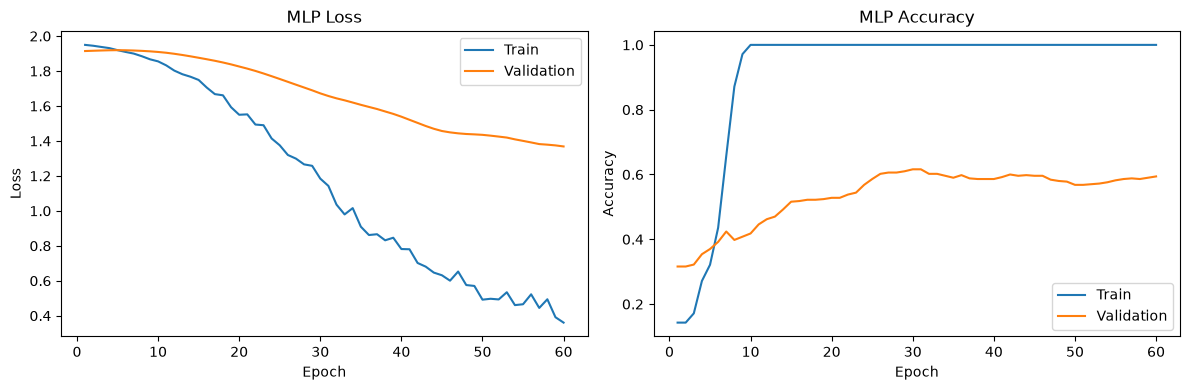


MLP training completed.
Best epoch: 30
Best validation accuracy: 0.6160

Training GCN
GCN | Epoch 010 | Train Loss: 1.7782 | Val Acc: 0.7060
GCN | Epoch 020 | Train Loss: 1.4153 | Val Acc: 0.7540
GCN | Epoch 030 | Train Loss: 1.0117 | Val Acc: 0.7980
GCN | Epoch 040 | Train Loss: 0.6803 | Val Acc: 0.8020
GCN | Epoch 050 | Train Loss: 0.5108 | Val Acc: 0.8060
GCN | Epoch 060 | Train Loss: 0.4106 | Val Acc: 0.8040
GCN | Epoch 070 | Train Loss: 0.3383 | Val Acc: 0.8020
GCN: Early stopping at epoch 78


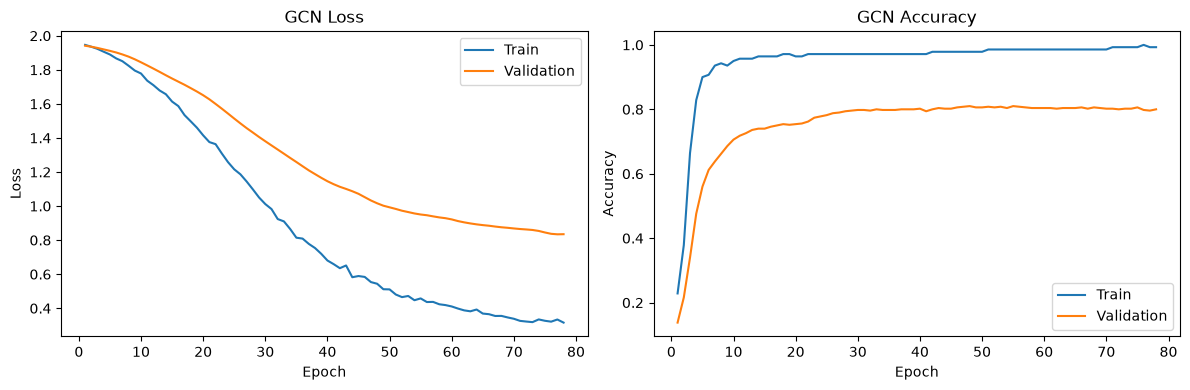


GCN training completed.
Best epoch: 48
Best validation accuracy: 0.8100

Training GAT
GAT | Epoch 010 | Train Loss: 1.8944 | Val Acc: 0.7260
GAT | Epoch 020 | Train Loss: 1.7907 | Val Acc: 0.7680
GAT | Epoch 030 | Train Loss: 1.6789 | Val Acc: 0.8060
GAT | Epoch 040 | Train Loss: 1.5538 | Val Acc: 0.7940
GAT | Epoch 050 | Train Loss: 1.4468 | Val Acc: 0.7860
GAT | Epoch 060 | Train Loss: 1.2841 | Val Acc: 0.8060
GAT | Epoch 070 | Train Loss: 1.1923 | Val Acc: 0.7980
GAT | Epoch 080 | Train Loss: 1.0901 | Val Acc: 0.8060
GAT | Epoch 090 | Train Loss: 1.0144 | Val Acc: 0.8120
GAT | Epoch 100 | Train Loss: 0.8553 | Val Acc: 0.8080
GAT | Epoch 110 | Train Loss: 0.8123 | Val Acc: 0.8020
GAT: Early stopping at epoch 114


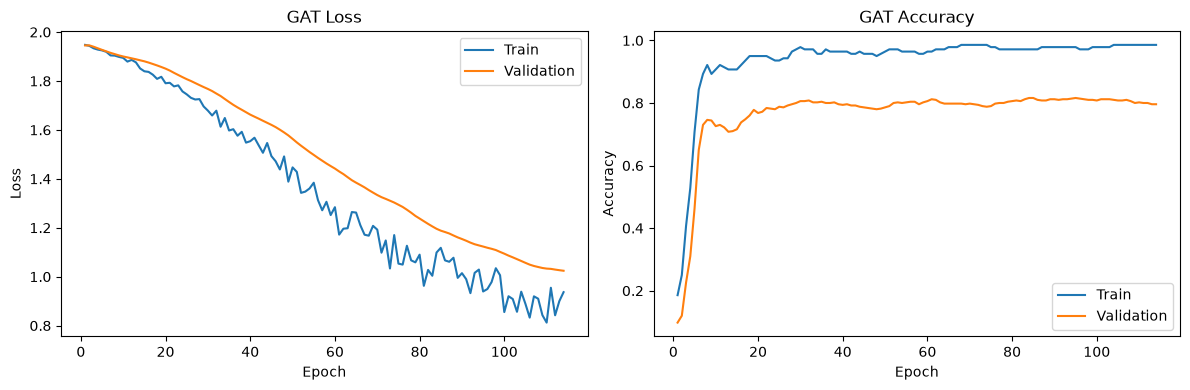


GAT training completed.
Best epoch: 84
Best validation accuracy: 0.8160


In [13]:
# Training

from src.train import train_model
from src.utils import set_seed

trained_models = {}
training_histories = {}

for model_name, config in model_configs.items():

    print("\n" + "=" * 60)
    print(f"Training {model_name}")
    print("=" * 60)

    set_seed(SEED)

    model = config["class"](**config["kwargs"])

    model, history = train_model(
        model=model,
        data=data,
        model_name=model_name,
        device=device,
        epochs=200,
        learning_rate=config["learning_rate"],
        weight_decay=config["weight_decay"],
        patience=30
    )

    trained_models[model_name] = model
    training_histories[model_name] = history

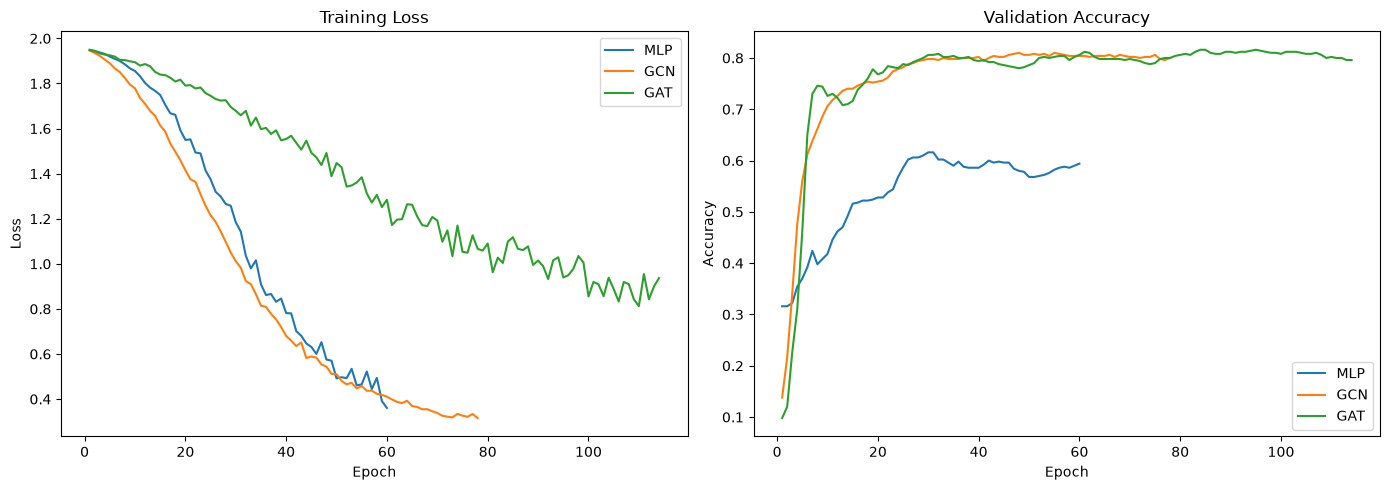

In [14]:
# Convergence

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, history in training_histories.items():

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=model_name
    )

    axes[1].plot(
        history["epoch"],
        history["val_acc"],
        label=model_name
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


MLP
accuracy: 0.5800
precision_macro: 0.5561
recall_macro: 0.5792
f1_macro: 0.5609


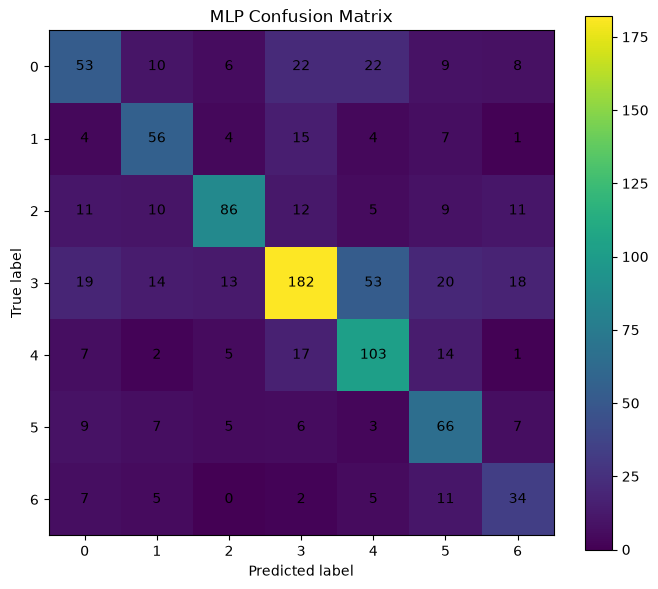


GCN
accuracy: 0.8270
precision_macro: 0.8081
recall_macro: 0.8235
f1_macro: 0.8136


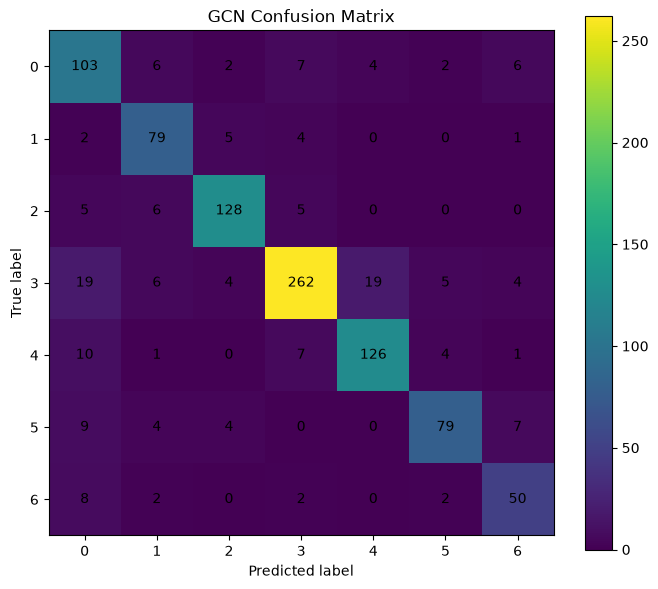


GAT
accuracy: 0.8240
precision_macro: 0.8051
recall_macro: 0.8239
f1_macro: 0.8131


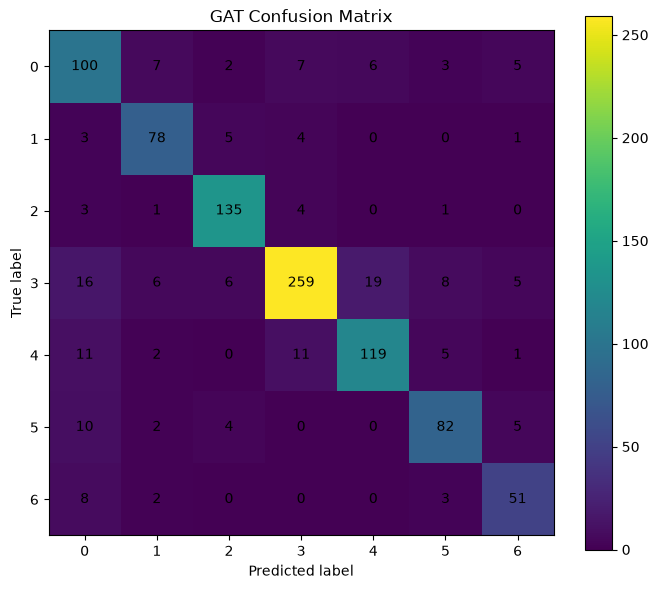

In [15]:
# Comparison

from src.evaluate import (
    evaluate_model,
    plot_confusion_matrix
)

neural_results = {}

for model_name, model in trained_models.items():

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    metrics, cm = evaluate_model(
        model=model,
        data=data,
        device=device,
        mask_name="test",
        num_classes=num_classes
    )

    neural_results[model_name] = metrics

    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value:.4f}")

    plot_confusion_matrix(cm, model_name)

In [31]:
# Spectral Clustering

from src.spectral import normalized_spectral_clustering

(
    cluster_labels,
    eigenvalues,
    spectral_embedding,
    spectral_diagnostics
) = normalized_spectral_clustering(
    data=data,
    num_clusters=num_classes,
    seed=SEED,
    gamma=5.0,
    feature_weight=0.5
)

print("Eigenvalues:")
print(eigenvalues)

print("\nEmbedding shape:")
print(spectral_embedding.shape)

print("\nAffinity diagnostics:")

for key, value in spectral_diagnostics.items():
    print(f"{key}: {value:.6f}")

print("\nCluster distribution:")

cluster_counts = np.bincount(
    cluster_labels,
    minlength=num_classes
)

for cluster_id, count in enumerate(cluster_counts):
    print(f"Cluster {cluster_id}: {count} nodes")

assert len(cluster_labels) == data.num_nodes
assert spectral_embedding.shape == (
    data.num_nodes,
    num_classes
)

print("\nSpectral clustering completed.")

Eigenvalues:
[-2.37544974e-17  2.53211367e-01  2.68821231e-01  2.76017245e-01
  2.80611586e-01  2.82350738e-01  2.84154707e-01]

Embedding shape:
(2708, 7)

Affinity diagnostics:
graph_mean_degree: 3.898080
feature_mean_degree: 1.949040
gamma: 5.000000
feature_weight: 0.500000

Cluster distribution:
Cluster 0: 64 nodes
Cluster 1: 434 nodes
Cluster 2: 1204 nodes
Cluster 3: 101 nodes
Cluster 4: 63 nodes
Cluster 5: 90 nodes
Cluster 6: 752 nodes

Spectral clustering completed.


In [32]:
# Mapping cluster to labels

from src.spectral import evaluate_spectral_clustering

y_true = data.y.cpu().numpy()

train_mask_np = data.train_mask.cpu().numpy()
test_mask_np = data.test_mask.cpu().numpy()

(
    spectral_metrics,
    cluster_mapping,
    spectral_predictions,
    train_contingency
) = evaluate_spectral_clustering(
    cluster_labels=cluster_labels,
    true_labels=y_true,
    train_mask=train_mask_np,
    test_mask=test_mask_np,
    embedding=spectral_embedding,
    num_classes=num_classes
)

print("Cluster -> Class mapping:")

for cluster_id, class_id in enumerate(cluster_mapping):
    print(
        f"Cluster {cluster_id} -> Class {class_id}"
    )

print("\nTraining cluster-class contingency table:")

contingency_df = pd.DataFrame(
    train_contingency,
    index=[f"Cluster {i}" for i in range(num_classes)],
    columns=[f"Class {i}" for i in range(num_classes)]
)

display(contingency_df)

print("\nSpectral metrics:")

for metric_name, value in spectral_metrics.items():
    print(f"{metric_name}: {value:.4f}")

Cluster -> Class mapping:
Cluster 0 -> Class 4
Cluster 1 -> Class 2
Cluster 2 -> Class 5
Cluster 3 -> Class 4
Cluster 4 -> Class 4
Cluster 5 -> Class 3
Cluster 6 -> Class 1

Training cluster-class contingency table:


,Class 0,Class 1,Class 2,Class 3,Class 4,Class 5,Class 6
Cluster 0,0,0,0,0,2,0,0
Cluster 1,0,2,19,1,0,0,0
Cluster 2,7,4,1,14,11,16,14
Cluster 3,0,0,0,0,5,0,0
Cluster 4,0,0,0,0,1,0,0
Cluster 5,0,0,0,4,0,0,0
Cluster 6,13,14,0,1,1,4,6



Spectral metrics:
accuracy: 0.3620
precision_macro: 0.4395
recall_macro: 0.4059
f1_macro: 0.3197
nmi: 0.3548
ari: 0.2369


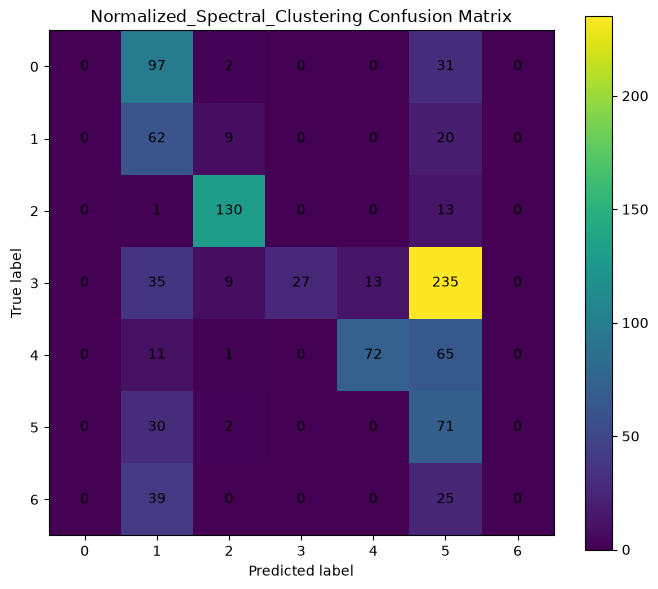

In [29]:
# When spectral gets confused

from sklearn.metrics import confusion_matrix

spectral_cm = confusion_matrix(
    y_true[test_mask_np],
    spectral_predictions,
    labels=np.arange(num_classes)
)

plot_confusion_matrix(
    spectral_cm,
    "Normalized_Spectral_Clustering"
)

In [30]:
# Full comparison

all_results = {}

for model_name, metrics in neural_results.items():
    all_results[model_name] = metrics

all_results["Normalized Spectral Clustering"] = {
    "accuracy": spectral_metrics["accuracy"],
    "precision_macro": spectral_metrics["precision_macro"],
    "recall_macro": spectral_metrics["recall_macro"],
    "f1_macro": spectral_metrics["f1_macro"]
}

results_df = pd.DataFrame.from_dict(
    all_results,
    orient="index"
)

results_df.index.name = "Model"

display(results_df.round(4))

results_df.to_csv(
    METRICS_DIR / "model_comparison.csv"
)

,accuracy,precision_macro,recall_macro,f1_macro
Model,,,,
MLP,0.580,0.5561,0.5792,0.5609
GCN,0.827,0.8081,0.8235,0.8136
GAT,0.824,0.8051,0.8239,0.8131
Normalized Spectral Clustering,0.362,0.4395,0.4059,0.3197


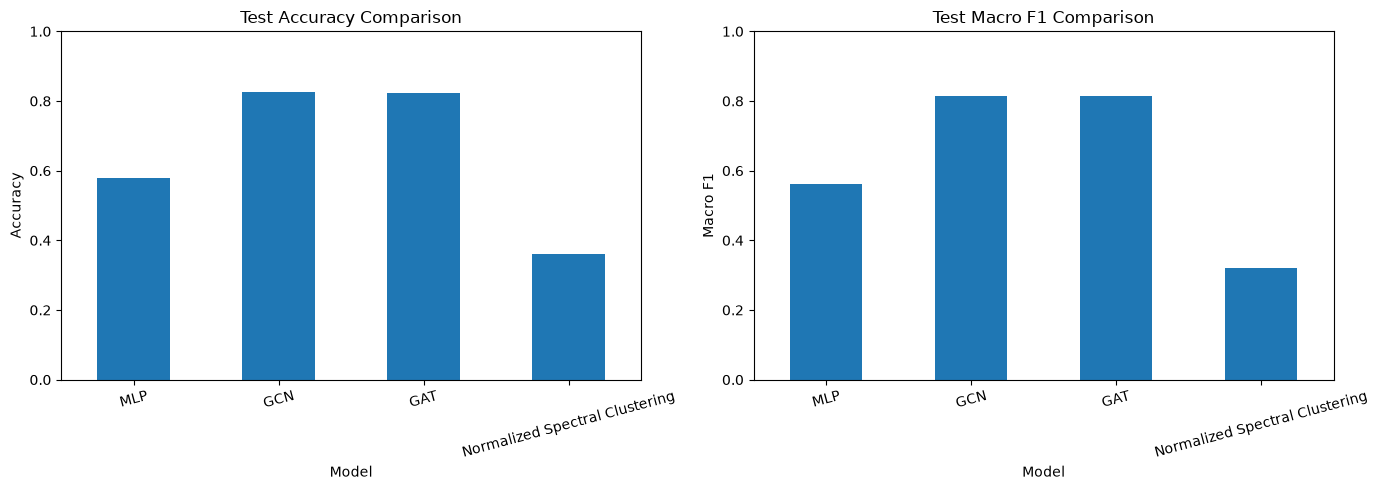

In [33]:
# Accuracy and F1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

results_df["accuracy"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Test Accuracy Comparison")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=15)

results_df["f1_macro"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Test Macro F1 Comparison")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Macro F1")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Summary

import pandas as pd
from src.config import DATASET_NAME, SEED, METRICS_DIR
from src.data import get_graph_components
from src.utils import save_json, create_project_dirs

num_components, _, component_sizes = get_graph_components(data)

experiment_summary = {
    "dataset": DATASET_NAME,

    "num_nodes": int(data.num_nodes),
    "num_edges": int(data.edge_index.size(1) // 2),
    "num_features": int(num_features),
    "num_classes": int(num_classes),

    "num_connected_components": int(num_components),
    "smallest_component_size": int(component_sizes.min()),
    "largest_component_size": int(component_sizes.max()),

    "train_nodes": int(data.train_mask.sum().item()),
    "validation_nodes": int(data.val_mask.sum().item()),
    "test_nodes": int(data.test_mask.sum().item()),

    "seed": int(SEED),
    "device": str(device),

    "spectral_method": "Feature-Augmented Normalized Spectral Clustering",
    "spectral_gamma": 5.0,
    "spectral_feature_weight": 0.5
}

display(
    pd.DataFrame(
        experiment_summary.items(),
        columns=["Property", "Value"]
    )
)

save_json(
    experiment_summary,
    METRICS_DIR / "experiment_summary.json"
)

,Property,Value
0,dataset,Cora
1,num_nodes,2708
2,num_edges,5278
3,num_features,1433
4,num_classes,7
5,num_connected_components,78
6,smallest_component_size,2
7,largest_component_size,2485
8,train_nodes,140
9,validation_nodes,500
